# EcoSort Waste Management Assistant
# Module 8 Summative Lab

## Overview

You are a data scientist at "EcoSort," a technology company that specializes in developing AI solutions for waste management. EcoSort has partnered with Metro City's waste management department to develop an intelligent waste management assistant that can help residents properly dispose of waste items so less time is spent sorting material at facilities.

This assistant needs to:

1. Identify waste materials from images uploaded by residents (CNN)
2. Classify waste items based on text descriptions provided by residents (RNN/Transformer)
3. Generate specific recycling instructions based on identified waste type and city policies (Generative Transformer with RAG)

Your task is to build this integrated system using the RealWaste dataset along with generated text data that simulates real-world waste management operations.

## Part 1: Dataset Exploration and Preparation

In this section, you will explore and prepare the datasets for your models.

### 1.1 Load and Explore the RealWaste Dataset

In [1]:
# Import necessary libraries
# Core Python, file handling, data manipulation, and reproducibility
import os
import pathlib
import glob
import json
import re
import random
import pandas as pd
import numpy as np

# Plotting and visualization
import matplotlib as mpl
import matplotlib.pyplot as plt

# Image loading and inspection
from PIL import Image

# TensorFlow / Keras: image classification, transfer learning, training,
# callbacks, metrics, dataset loading, and model saving/loading
import tensorflow as tf
from tensorflow import keras
from tensorflow import cast
from tensorflow.keras import Sequential, Model
from tensorflow.keras.models import save_model, load_model
from tensorflow.keras.layers import (
    Dense,
    Conv2D,
    Flatten,
    MaxPooling2D,
    GlobalAveragePooling2D,
    Input,
)
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical, image_dataset_from_directory
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.optimizers import Adam
from tensorflow.data import AUTOTUNE as autotune
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from tensorflow.keras.metrics import Accuracy, Precision, Recall

# Scikit-learn: text feature extraction, data splitting, label encoding,
# similarity search, and model evaluation
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_fscore_support,
)
from sklearn.metrics.pairwise import cosine_similarity

# PyTorch: tensor operations and BERT inference
import torch

# Hugging Face Transformers: BERT tokenization, classification, and training
from transformers import (
    BertTokenizer,
    BertForSequenceClassification,
    Trainer,
    TrainingArguments,
    EvalPrediction,
    EarlyStoppingCallback,
)

# Hugging Face Datasets: converting tabular text data into model-ready datasets
from datasets import load_dataset, Dataset

# Sentence Transformers: semantic embeddings for the RAG retrieval system
from sentence_transformers import SentenceTransformer


# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)

In [2]:
# TODO: Load and explore the RealWaste dataset
# - Dataset structure
# - Distribution of waste categories
# - Image characteristics (resolution, quality, background)

# Your code here

data_dir = pathlib.Path('realwaste')
# Calculate the total number of classes automatically from the directory structure
num_classes = len([item for item in data_dir.glob('*') if item.is_dir()])
print(f"Number of classes: {num_classes}")

# List all class folders
class_names = sorted([item.name for item in data_dir.glob('*') if item.is_dir()])
print(f"Class names: {class_names}")

# Count all images
image_count = len(list(data_dir.glob('*/*.jpg'))) + len(list(data_dir.glob('*/*.png')))
print(f"Total images found: {image_count}")

Number of classes: 9
Class names: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']
Total images found: 4752


In [3]:
# Count images in each category folder
category_counts = {}
for cls in class_names:
    cls_path = data_dir / cls
    # Count both .jpg and .png images in this folder
    count = len(list(cls_path.glob('*.jpg'))) + len(list(cls_path.glob('*.png')))
    category_counts[cls] = count

# Convert to a DataFrame for easy viewing
df_counts = pd.DataFrame(list(category_counts.items()), columns=['Category', 'Image Count'])
df_counts = df_counts.sort_values(by='Image Count', ascending=False).reset_index(drop=True)

print("--- Class Breakdown ---")
print(df_counts.to_string(index=False))

--- Class Breakdown ---
           Category  Image Count
            Plastic          921
              Metal          790
              Paper          500
Miscellaneous Trash          495
          Cardboard          461
         Vegetation          436
              Glass          420
      Food Organics          411
      Textile Trash          318


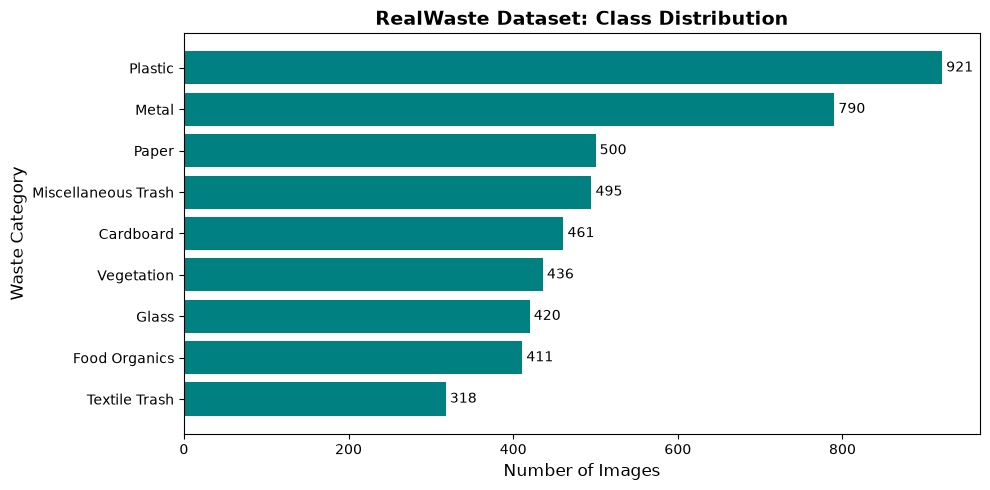

In [4]:
#GRAPH SHOWING DISTRIBUTION IN THE DIFFERENT CLASSES
# Plot the distribution using pure Matplotlib
plt.figure(figsize=(10, 5))
bars = plt.barh(df_counts['Category'], df_counts['Image Count'], color='teal')

plt.title('RealWaste Dataset: Class Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Number of Images', fontsize=12)
plt.ylabel('Waste Category', fontsize=12)
plt.gca().invert_yaxis()  # Put highest count at the top

# Add numbers at the end of each bar
for bar in bars:
    width = bar.get_width()
    plt.text(width + 5, bar.get_y() + bar.get_height() / 2, f'{int(width)}',
             ha='left', va='center', fontsize=10)

plt.tight_layout()
plt.show()

In [5]:
# - Image characteristics (resolution, quality, background)

image_data = []

# Supported image formats
image_extensions = {'.jpg', '.jpeg', '.png'}

# Find all image files inside the category folders
image_files = [
    file for file in data_dir.glob('*/*')
    if file.is_file() and file.suffix.lower() in image_extensions
]

for image_path in image_files:
    try:
        with Image.open(image_path) as image:
            image_data.append({
                "category": image_path.parent.name,
                "width": image.width,
                "height": image.height,
                "format": image.format,
                "mode": image.mode
            })
    except Exception as e:
        print(f"Could not read {image_path}: {e}")

# Convert image information into a DataFrame
image_df = pd.DataFrame(image_data)

print("\n--- Image Characteristics ---")
display(image_df.sample(5))


--- Image Characteristics ---


,category,width,height,format,mode
1962,Metal,524,524,JPEG,RGB
1536,Metal,524,524,JPEG,RGB
297,Cardboard,524,524,JPEG,RGB
2488,Miscellaneous Trash,524,524,JPEG,RGB
4320,Vegetation,524,524,JPEG,RGB


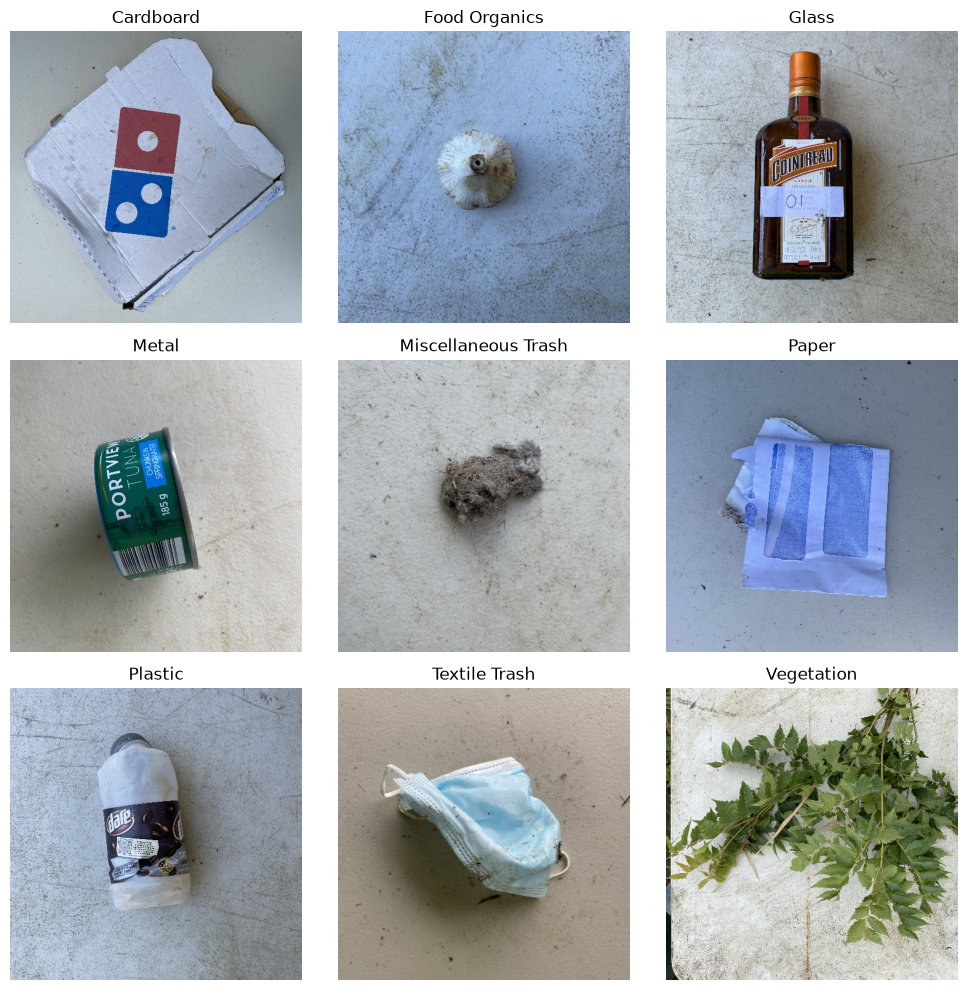

Image sizes in a sample of 100: {(524, 524)}
Image modes in a sample of 100: {'RGB'}


In [6]:
#DISPLAYING A FEW IMAGES TO ENSURE WE HAVE LOADED CORRECTLY
# One random image per class, plus a check on image size and mode
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for ax, cls in zip(axes.flat, class_names):
    path = random.choice(list((data_dir / cls).glob('*.jpg')) + list((data_dir / cls).glob('*.png')))
    ax.imshow(Image.open(path))
    ax.set_title(cls)
    ax.axis('off')
plt.tight_layout()
plt.show()

all_paths = list(data_dir.glob('*/*.jpg')) + list(data_dir.glob('*/*.png'))
sample = random.sample(all_paths, min(100, len(all_paths)))
print("Image sizes in a sample of 100:", {Image.open(p).size for p in sample})
print("Image modes in a sample of 100:", {Image.open(p).mode for p in sample})

### 1.2 Explore Text Datasets

In [7]:
# TODO: Load and explore the waste description text data
# - Load waste_descriptions.csv
# - Analyze vocabulary and structure
# - Understand the distribution of categories

# Your code here
df= pd.read_csv('waste_descriptions.csv')

print("=== Dataset Overview ===")
print(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print("\nColumns:", df.columns.tolist())
print("\nSample Rows:")
print(df.head(3))

# Category Distribution Analysis
print("\n=== Category Distribution ===")
category_counts = df['category'].value_counts()
category_pcts = df['category'].value_counts(normalize=True) * 100
dist_df = pd.DataFrame({'Count': category_counts, 'Percentage (%)': category_pcts.round(2)})
print(dist_df)

=== Dataset Overview ===
Shape: 5000 rows, 5 columns

Columns: ['description', 'category', 'disposal_instruction', 'common_confusion', 'material_composition']

Sample Rows:
                                         description       category  \
0                           soiled silver tablecloth  Textile Trash   
1                        folded glass bottle leaking          Glass   
2  large Supermarket vegetable waste with food re...  Food Organics   

                                disposal_instruction common_confusion  \
0  Look for textile recycling programs in your area.              NaN   
1     Remove caps, lids, and corks before recycling.              NaN   
2   If no compost available, place in general waste.              NaN   

                                material_composition  
0  Fabric made from natural or synthetic fibers, ...  
1  Silica-based material, may contain additives f...  
2  Biodegradable matter derived from plant or ani...  

=== Category Distribution ==

In [8]:
# Structural & Text Length Analysis
df['word_count'] = df['description'].astype(str).apply(lambda x: len(x.split()))
df['char_count'] = df['description'].astype(str).apply(len)

print("\n=== Text Structure Summary ===")
print(f"Average Words per Description : {df['word_count'].mean():.2f}")
print(f"Min / Max Word Count          : {df['word_count'].min()} / {df['word_count'].max()}")
print(f"Average Characters per String : {df['char_count'].mean():.2f}")


=== Text Structure Summary ===
Average Words per Description : 4.85
Min / Max Word Count          : 1 / 10
Average Characters per String : 33.41


In [9]:
# TODO: Load and explore the waste policy documents
# - Load waste_policy_documents.csv
# - Understand document organization and language

# Your code here
with open("waste_policy_documents.json", "r", encoding="utf-8") as file: #read mode,
    json_data = json.load(file) #translates the JSON text format into native Python data types

df_json = pd.DataFrame(json_data) #Converting to a Table

# - Understand document organization and language

print(" DOCUMENT STRUCTURE & METADATA")
print(df_json.info())

# Show the top 5 records to visually inspect formatting and layout
print(df_json.head())


 DOCUMENT STRUCTURE & METADATA
<class 'pandas.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   policy_id           14 non-null     int64 
 1   policy_type         14 non-null     str   
 2   categories_covered  14 non-null     object
 3   effective_date      14 non-null     str   
 4   document_text       14 non-null     str   
 5   jurisdiction        14 non-null     str   
dtypes: int64(1), object(1), str(4)
memory usage: 10.8+ KB
None
   policy_id                         policy_type categories_covered  \
0          1  Textile Trash Recycling Guidelines    [Textile Trash]   
1          2          Glass Recycling Guidelines            [Glass]   
2          3  Food Organics Recycling Guidelines    [Food Organics]   
3          4        Plastic Recycling Guidelines          [Plastic]   
4          5     Vegetation Recycling Guidelines       [Vegetation]   

  e

In [10]:
#Document Analysis

# Defining target column
text_col = "document_text"

# counting how many documents fall into different categories (like jurisdiction)
for metadata_col in ["jurisdiction", "categories_covered", "policy_type"]:
    if metadata_col in df_json.columns:
        print(f"\n Document Distribution By: {metadata_col}")
        print(df_json[metadata_col].value_counts())


 Document Distribution By: jurisdiction
jurisdiction
Metro City    14
Name: count, dtype: int64

 Document Distribution By: categories_covered
categories_covered
[Textile Trash]                                             1
[Glass]                                                     1
[Food Organics]                                             1
[Plastic]                                                   1
[Vegetation]                                                1
[Cardboard]                                                 1
[Metal]                                                     1
[Paper]                                                     1
[Miscellaneous Trash]                                       1
[Plastic, Miscellaneous Trash, Vegetation]                  1
[Plastic, Metal, Glass, Miscellaneous Trash, Vegetation]    1
[Food Organics, Metal, Miscellaneous Trash]                 1
[Cardboard, Glass, Textile Trash]                           1
[Cardboard, Vegetation, Metal, 

In [11]:

if text_col in df_json.columns:
    # Calculate word count for each document to understand how long the documents are
    df_json["word_count"] = (df_json[text_col].astype(str).apply(lambda x: len(x.split())))

    # Output statistical breakdown (Mean length, Min, Max, Quantiles)
    print("\n Document Length ")
    display(df_json["word_count"].describe())


 Document Length 


count     14.000000
mean     101.785714
std       15.115853
min       86.000000
25%       94.250000
50%       99.000000
75%      102.000000
max      146.000000
Name: word_count, dtype: float64

### 1.3 Create Data Pipelines

In [12]:
# Run this code to setup the images properly into train, validation, and test sets
# Set your data directory path - update this with your actual path


# Parameters
BATCH_SIZE = 32
IMG_HEIGHT = 224
IMG_WIDTH = 224

# Create a dataset using tf.keras.utils.image_dataset_from_directory
# This will automatically split the data into training and validation sets
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,  # 20% for validation
    subset="training",
    seed=42,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode='categorical',  # For one-hot encoded labels
    shuffle=True
)

validation_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,  # 20% for validation
    subset="validation",
    seed=42,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode='categorical',  # For one-hot encoded labels
    shuffle=True
)

# Create a separate test dataset by taking part of the validation set
# First, let's get the number of batches in the validation set
val_batches = tf.data.experimental.cardinality(validation_ds)
test_dataset = validation_ds.take(val_batches // 2)
validation_ds = validation_ds.skip(val_batches // 2)

print(f"Number of training batches: {tf.data.experimental.cardinality(train_ds)}")
print(f"Number of validation batches: {tf.data.experimental.cardinality(validation_ds)}")
print(f"Number of test batches: {tf.data.experimental.cardinality(test_dataset)}")

# Configure dataset for performance
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
validation_ds = validation_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.cache().prefetch(buffer_size=AUTOTUNE)

Found 4752 files belonging to 9 classes.
Using 3802 files for training.
Found 4752 files belonging to 9 classes.
Using 950 files for validation.
Number of training batches: 119
Number of validation batches: 15
Number of test batches: 15


In [13]:
# TODO: Create a text preprocessing pipeline
# - Tokenization
# - Text cleaning
# - Split data into train and test
# - Create embeddings/features

# Your code here
#TEXT CLEANING
#Step 1 - is to define a function which cleans each waste description 
text_df = df.copy()
def clean_text(text):
        text = re.sub(r"\s+", " ", text) #replaces multiple spaces with justa single text
        text = text.strip() #removes unnececssary spacing

        return text

#Applying the cleaning function to all waste descriptions
text_df["clean_description"] = text_df["description"].apply(clean_text)

#ENCODING LABELS
label_encoder = LabelEncoder () # initialize
label_encoder.fit(df["category"])
text_df["label"] = label_encoder.transform(df["category"])

# View mapping of category names to numbers
mapping = dict(zip(label_encoder.classes_, range(len(label_encoder.classes_))))
print("Category Mapping:", mapping)
print(text_df["label"].head())

print(text_df["clean_description"].iloc[0])

Category Mapping: {'Cardboard': 0, 'Food Organics': 1, 'Glass': 2, 'Metal': 3, 'Miscellaneous Trash': 4, 'Paper': 5, 'Plastic': 6, 'Textile Trash': 7, 'Vegetation': 8}
0    7
1    2
2    1
3    7
4    1
Name: label, dtype: int32
soiled silver tablecloth


In [14]:
train_df, hold_df = train_test_split(text_df, test_size=0.2, random_state=42, stratify= text_df["label"])
val_df, test_df = train_test_split(hold_df, test_size=0.5, random_state=42, stratify= hold_df["label"])

# Initialize Tokenizer
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

def tokenize_function (examples):
    return tokenizer(
        examples["description"],
        max_length = 64, #BERT is designed to handle input sequence of 512 tokens. If no description exceeds 512, the max length can be left unset and defaults to models max length
        padding = 'max_length', #for description shorter than 512, padding tokens are added to extend tokens to 512
        truncation = True, #when input sequence does not fit limit
        return_tensors = 'pt')
# Convert pandas DataFrames directly to Hugging Face Datasets
train_dataset = Dataset.from_pandas(train_df[["description", "label"]])
val_dataset = Dataset.from_pandas(val_df[["description", "label"]])
test_text_dataset = Dataset.from_pandas(test_df[["description", "label"]])

# Tokenize datasets
tokenized_train = train_dataset.map(tokenize_function, batched=True)
tokenized_val = val_dataset.map(tokenize_function, batched=True)
tokenized_test = test_text_dataset.map(tokenize_function, batched=True)

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

In [15]:
# TODO: Prepare documents for RAG
# - Document preprocessing
# - Create embeddings for retrieval

# Your code here
#Turning each row into an enriched block of text since machine learning models cannot read a database table
documents = [] #the empty list to store our final text blocks
for idx, row in df_json.iterrows(): #Looping through the table row by row
    # Cleaning up newline strings (\n\n) present in the document text column and replacing with a clean single space
    cleaned_doc_text = str(row['document_text']).replace('\\n', ' ')

    # Forming a single text block for the vector engine (policy_type categories_covered, jurisdiction, and actual text rules.
    text_block = (
        f"Policy Type: {row['policy_type']}. "
        f"Categories Covered: {row['categories_covered']}. "
        f"Jurisdiction: {row['jurisdiction']}. "
        f"Guidelines: {cleaned_doc_text}")

    documents.append(text_block) #Adding the newly created long sentence into the documents list

# - Create embeddings for retrieval
vectorizer = TfidfVectorizer(stop_words='english') #Initializing the text-to-number converter (Vectorizer) & ignoring filler words
tfidf_matrix = vectorizer.fit_transform(documents) #Converting documents into a matrix and learning all the unique words across documents,
                                                    #transofmr calculating a score for each word based on its importance.

## Part 2: Waste Material Classification with CNN

In this section, you will build a CNN model to classify waste materials from images.

### 2.1 Preprocess Images

In [16]:
# TODO: Implement image preprocessing
# - Apply the preprocessing pipeline created earlier

# Your code here
def preprocess_images(image, label):
    image = preprocess_input(image)
    return image, label

train_ds = train_ds.map(
    preprocess_images,
    num_parallel_calls=tf.data.AUTOTUNE
)

validation_ds = validation_ds.map(
    preprocess_images,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_dataset = test_dataset.map(
    preprocess_images,
    num_parallel_calls=tf.data.AUTOTUNE

)


### 2.2 Implement CNN Model with Transfer Learning

In [17]:
# TODO: Select an appropriate base model and implement transfer learning
# - Choose from MobileNet, EfficientNet, etc.
# - Add custom classification layers for the 9 waste categories
# - Configure loss function and metrics

# Your code here
epochs = 200

# Initialize model
base_model = MobileNetV2(input_shape = (IMG_HEIGHT, IMG_WIDTH, 3),
                         include_top = False,
                         weights = 'imagenet'
                         )
# Freeze learning on feature extraction layers to prevent updating their weights during training
base_model.trainable = False

# Create classification layers of InceptionV3
global_average_pool = GlobalAveragePooling2D()        # Global average pooling
classifier = Dense(units = 9, activation = 'softmax') # 1000 neuron fully connected layer with ReLU activation

# Connect input layer, base model and output layers
inputs = Input(shape = (IMG_HEIGHT, IMG_WIDTH, 3)) # Input layer: 524x524x3 RGB images
model = base_model(inputs)                         # Feature extraction layers of InceptionV3
model = global_average_pool(model)                 # Global average pooling layer
outputs = classifier(model)                        # Fully connected layer: 8 neuron softmax activation for classification


### 2.3 Train and Evaluate the Model

In [18]:
# TODO: Train the CNN model
# - Use appropriate batch size and epochs
# - Implement regularization to prevent overfitting
# - Monitor training and validation metrics

# Your code here
# Callback to stop model training when model converges
model_callback = EarlyStopping(monitor='val_loss', patience=5, mode='min')
# Learning rates
learn_rate_fc = 1e-3  # Fully connected layers
# CHANGED: was '' for both, which saved to the root folder
os.makedirs('models', exist_ok=True)
best_model_path_fc = 'models'
dataset_name = 'realwaste'
# Build MobileNetV2 model
mobile_net_v2 = Model(inputs, outputs, name = 'MobileNetV2')
# Compile model:
  # Adam algorithm optimization
  # Categorical crossentropy loss function for multilabel classification
  # Metrics: accuracy, precision, recall
mobile_net_v2.compile(
    optimizer = Adam(learn_rate_fc),
    loss = 'categorical_crossentropy',
    metrics = ['accuracy', Precision(), Recall()]
)

# ---------------- Train MobileNet V2 Fully Connected Layers --------------- #
print('\n|------------------------------| Training Fully Connected Layers |--------------------------------|\n')

# Define checkpoint to save model after every epoch
model_checkpoint_fc = ModelCheckpoint(best_model_path_fc + '/mobilenet_v2-' + dataset_name + '-{epoch:02d}-{val_accuracy:.4f}.hdf5', save_best_only = True, save_weights_only = False, mode= 'auto')

# Train model
history_fc= mobile_net_v2.fit(
    train_ds,
    validation_data = validation_ds,
    epochs = epochs,
    verbose = 1,
    callbacks = [model_checkpoint_fc, model_callback]
)

print('\n|--------------------------| Fully Connected Layers Training Complete |---------------------------|\n')


|------------------------------| Training Fully Connected Layers |--------------------------------|

Epoch 1/200


119/119 [==============================] - ETA: 0s - loss: 1.1988 - accuracy: 0.5831 - precision: 0.7817 - recall: 0.3824

c:\Users\laureennyambura\anaconda3\envs\ai-env3\Lib\site-packages\keras\src\engine\training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


119/119 [==============================] - 110s 877ms/step - loss: 1.1988 - accuracy: 0.5831 - precision: 0.7817 - recall: 0.3824 - val_loss: 0.7845 - val_accuracy: 0.7404 - val_precision: 0.8294 - val_recall: 0.6000
Epoch 2/200
119/119 [==============================] - 90s 751ms/step - loss: 0.6806 - accuracy: 0.7693 - precision: 0.8558 - recall: 0.6652 - val_loss: 0.6520 - val_accuracy: 0.7638 - val_precision: 0.8641 - val_recall: 0.6766
Epoch 3/200
119/119 [==============================] - 92s 773ms/step - loss: 0.5447 - accuracy: 0.8193 - precision: 0.8850 - recall: 0.7446 - val_loss: 0.6003 - val_accuracy: 0.7787 - val_precision: 0.8619 - val_recall: 0.7170
Epoch 4/200
119/119 [==============================] - 99s 830ms/step - loss: 0.4611 - accuracy: 0.8543 - precision: 0.9006 - recall: 0.7864 - val_loss: 0.5739 - val_accuracy: 0.7851 - val_precision: 0.8625 - val_recall: 0.7340
Epoch 5/200
119/119 [==============================] - 95s 795ms/step - loss: 0.4009 - accuracy: 0.

[fully connected layers only] Test loss: 0.5802 | Accuracy: 0.7979 | Precision: 0.8273 | Recall: 0.7583

                     precision    recall  f1-score   support

          Cardboard       0.71      0.81      0.76        37
      Food Organics       0.86      0.93      0.89        40
              Glass       0.74      0.66      0.69        38
              Metal       0.89      0.82      0.85        93
Miscellaneous Trash       0.66      0.65      0.65        48
              Paper       0.81      0.88      0.84        58
            Plastic       0.70      0.84      0.76        85
      Textile Trash       0.91      0.65      0.76        46
         Vegetation       1.00      0.91      0.96        35

           accuracy                           0.80       480
          macro avg       0.81      0.79      0.80       480
       weighted avg       0.81      0.80      0.80       480



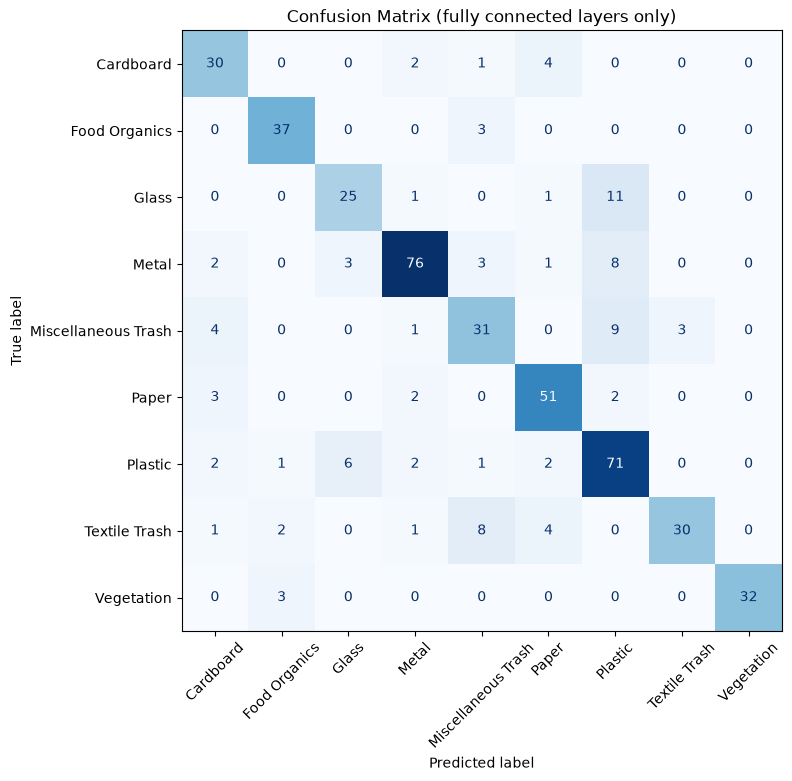

Total errors: 97 of 480

Most common mistakes (true -> predicted):
Glass -> Plastic                        11
Miscellaneous Trash -> Plastic           9
Metal -> Plastic                         8
Textile Trash -> Miscellaneous Trash     8
Plastic -> Glass                         6
Miscellaneous Trash -> Cardboard         4
Textile Trash -> Paper                   4
Cardboard -> Paper                       4
Miscellaneous Trash -> Textile Trash     3
Metal -> Miscellaneous Trash             3


In [19]:
# TODO: Evaluate model performance
# - Calculate accuracy on test set
# - Generate confusion matrix
# - Analyze error patterns

# Your code here
def evaluate_on_test(model, tag=''):
    # Accuracy, precision and recall on the test set
    test_loss, test_acc, test_prec, test_rec = model.evaluate(test_dataset, verbose=0)
    print(f"[{tag}] Test loss: {test_loss:.4f} | Accuracy: {test_acc:.4f} | "
          f"Precision: {test_prec:.4f} | Recall: {test_rec:.4f}\n")

    # Collect true and predicted labels in the same loop so they always line up
    y_true, y_pred = [], []
    for images, labels in test_dataset:
        probs = model.predict(images, verbose=0)
        y_true.extend(np.argmax(labels.numpy(), axis=1))
        y_pred.extend(np.argmax(probs, axis=1))
    y_true, y_pred = np.array(y_true), np.array(y_pred)

    # Per-class precision, recall and F1
    print(classification_report(y_true, y_pred, target_names=class_names))

    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(8, 8))
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
        ax=ax, xticks_rotation=45, cmap='Blues', colorbar=False)
    ax.set_title(f'Confusion Matrix ({tag})')
    plt.tight_layout()
    plt.show()

    # Error patterns: the most common true -> predicted mistakes
    errors = pd.Series([f"{class_names[t]} -> {class_names[p]}"
                        for t, p in zip(y_true, y_pred) if t != p])
    print(f"Total errors: {len(errors)} of {len(y_true)}")
    print("\nMost common mistakes (true -> predicted):")
    print(errors.value_counts().head(10).to_string())
    return test_acc

acc_fc = evaluate_on_test(mobile_net_v2, tag='fully connected layers only')

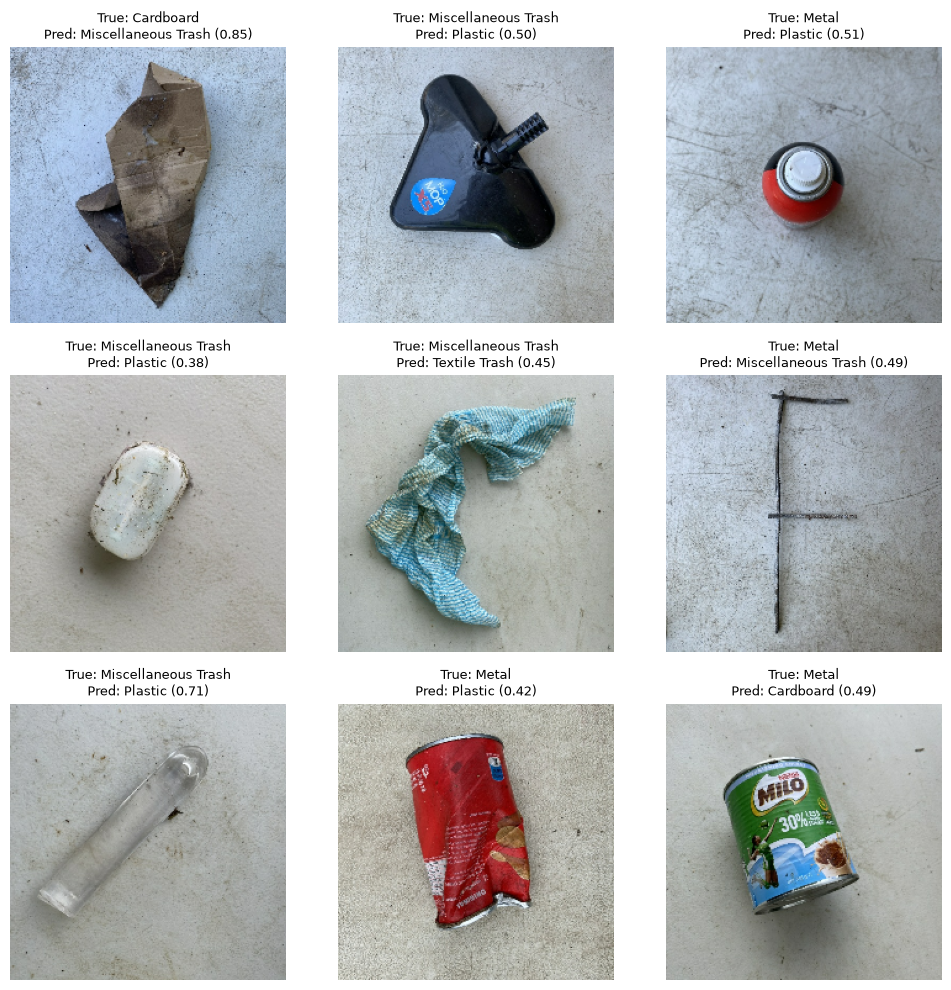

In [20]:
# look at some misclassified test images
def show_misclassified(model, n=9):
    plt.figure(figsize=(10, 10))
    shown = 0
    for images, labels in test_dataset:
        preds = model.predict(images, verbose=0)
        for img, true, pred in zip(images, labels, preds):
            t, p = np.argmax(true), np.argmax(pred)
            if t != p and shown < n:
                plt.subplot(3, 3, shown + 1)
                plt.imshow(np.clip((img.numpy() + 1) / 2, 0, 1))  # undo MobileNetV2 preprocessing for display
                plt.title(f"True: {class_names[t]}\nPred: {class_names[p]} ({pred[p]:.2f})", fontsize=9)
                plt.axis('off')
                shown += 1
        if shown >= n:
            break
    plt.tight_layout()
    plt.show()

show_misclassified(mobile_net_v2)

### 2.4 Fine-tune the Model

|------------------------| Fine Tuning Later Feature Extraction Layers |--------------------------|

Epoch 1/200
119/119 [==============================] - 130s 1s/step - loss: 0.4830 - accuracy: 0.8348 - precision_1: 0.8670 - recall_1: 0.7991 - val_loss: 0.7243 - val_accuracy: 0.7787 - val_precision_1: 0.8068 - val_recall_1: 0.7553
Epoch 2/200
119/119 [==============================] - 134s 1s/step - loss: 0.1880 - accuracy: 0.9369 - precision_1: 0.9467 - recall_1: 0.9243 - val_loss: 0.6632 - val_accuracy: 0.8000 - val_precision_1: 0.8285 - val_recall_1: 0.7915
Epoch 3/200
119/119 [==============================] - 114s 948ms/step - loss: 0.1145 - accuracy: 0.9611 - precision_1: 0.9657 - recall_1: 0.9566 - val_loss: 0.7354 - val_accuracy: 0.7936 - val_precision_1: 0.8178 - val_recall_1: 0.7830
Epoch 4/200
119/119 [==============================] - 131s 1s/step - loss: 0.0681 - accuracy: 0.9808 - precision_1: 0.9846 - recall_1: 0.9771 - val_loss: 0.5647 - val_accuracy: 0.8426 - val_pre

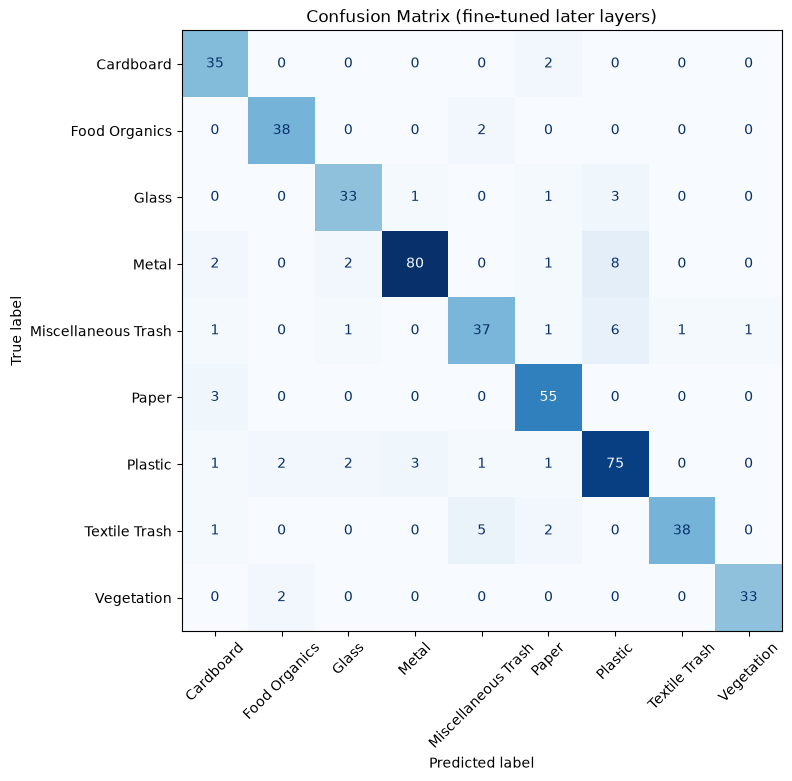

Total errors: 56 of 480

Most common mistakes (true -> predicted):
Metal -> Plastic                        8
Miscellaneous Trash -> Plastic          6
Textile Trash -> Miscellaneous Trash    5
Plastic -> Metal                        3
Glass -> Plastic                        3
Paper -> Cardboard                      3
Vegetation -> Food Organics             2
Plastic -> Food Organics                2
Metal -> Cardboard                      2
Cardboard -> Paper                      2


In [21]:
# TODO: Tune model parameters to improve performance
# - Adjust learning rate
# - Add regularization, dropout
# - Modify architecture if needed

# Your code here
# settings for fine-tuning (each stage uses a lower learning raten)
learn_rate_fe1 = 1e-4   # later feature extraction layers
split_layer = 100       # MobileNetV2 has ~154 layers: [1, split_layer) = early, [split_layer, end) = later
best_model_path_fe1 = 'models'


def unfreeze_feature_extraction_block(base_model, start, end):
    """Freeze everything in the base model, then unfreeze layers[start:end] (BatchNorm stays frozen)."""
    base_model.trainable = True
    for i, layer in enumerate(base_model.layers):
        layer.trainable = (start <= i < end) and not isinstance(layer, tf.keras.layers.BatchNormalization)

# ----------- Train MobileNet V2 Later Feature Extraction Layers ----------- #
print('|------------------------| Fine Tuning Later Feature Extraction Layers |--------------------------|\n')

# The model already holds its best weights (restore_best_weights=True), so no need to reload from disk
unfreeze_feature_extraction_block(base_model, split_layer, len(base_model.layers))

# Recompile is required after changing which layers are trainable; lower learning rate reduces overfitting
mobile_net_v2.compile(
    optimizer = Adam(learn_rate_fe1),
    loss = 'categorical_crossentropy',
    metrics = ['accuracy', Precision(), Recall()]
)

# Define checkpoint to save best model
best_model_checkpoint_fe1 = ModelCheckpoint(best_model_path_fe1 + '/mobilenet_v2-' + dataset_name + '-fe1-{epoch:02d}-{val_accuracy:.4f}.keras', save_best_only = True, save_weights_only = False, mode= 'auto')

# Fine tune model
history_fe1 = mobile_net_v2.fit(
    train_ds,
    validation_data = validation_ds,
    epochs = epochs,
    verbose = 1,
    callbacks = [best_model_checkpoint_fe1, model_callback]
)

print('\n|--------------------| Fine Tuning Later Feature Extraction Layers Complete |---------------------|\n')
acc_fe1 = evaluate_on_test(mobile_net_v2, tag='fine-tuned later layers')

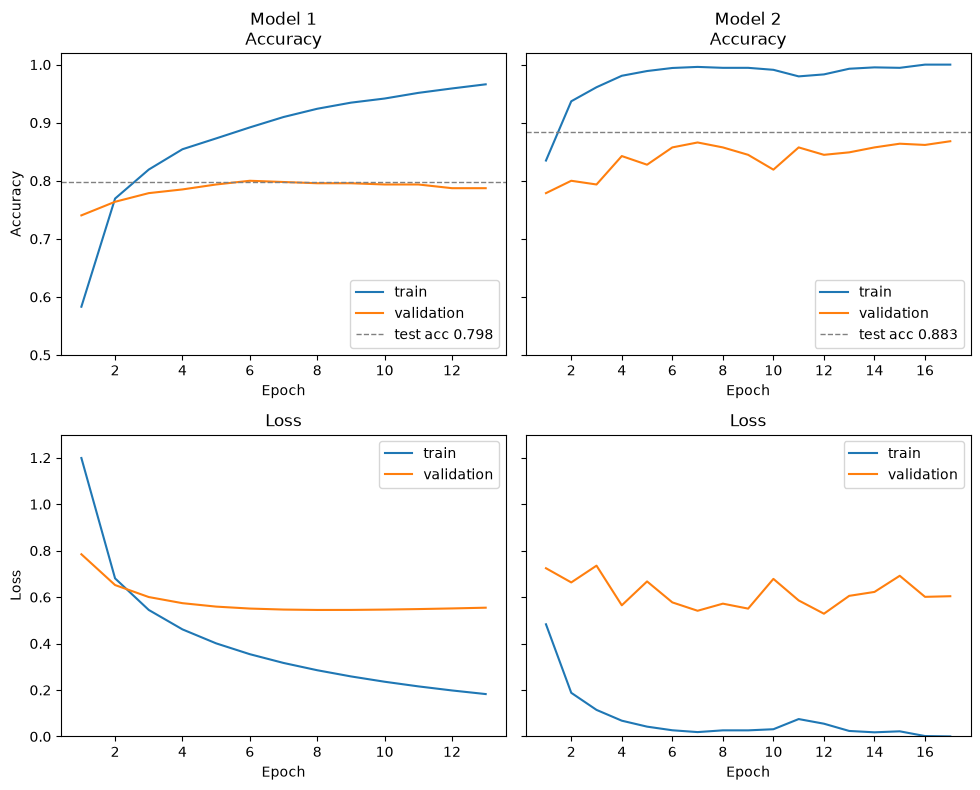

In [22]:
def plot_history_grid(histories, names, test_accs):
    fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharey='row')
    for j, (h, name, ta) in enumerate(zip(histories, names, test_accs)):
        hist = h.history
        ep = range(1, len(hist['loss']) + 1)

        # Row 1: accuracy
        ax = axes[0, j]
        ax.plot(ep, hist['accuracy'], label='train')
        ax.plot(ep, hist['val_accuracy'], label='validation')
        ax.axhline(ta, ls='--', color='gray', lw=1, label=f'test acc {ta:.3f}')
        ax.set_title(f'{name}\nAccuracy')
        ax.set_ylim(0.5, 1.02)
        ax.set_xlabel('Epoch')
        ax.legend(loc='lower right')

        # Row 2: loss (linear scale, same range in every column)
        lx = axes[1, j]
        lx.plot(ep, hist['loss'], label='train')
        lx.plot(ep, hist['val_loss'], label='validation')
        lx.set_title('Loss')
        lx.set_ylim(0, 1.3)
        lx.set_xlabel('Epoch')
        lx.legend(loc='upper right')

    axes[0, 0].set_ylabel('Accuracy')
    axes[1, 0].set_ylabel('Loss')
    plt.tight_layout()
    plt.show()

plot_history_grid(
    [history_fc, history_fe1],
    ['Model 1', 'Model 2'],
    [acc_fc, acc_fe1]
)



### Model 1: Training Only the Final Decision Layers

**What we did.** Instead of building an image classifier from nothing, we started with MobileNetV2, a model that has already learned to recognise millions of everyday photos. For this first model we locked all of its existing knowledge in place (called "freezing") and trained only the small final section that takes what the model sees and decides which of the 9 waste categories it belongs to. I used a learning rate of 1e-5 (small, careful steps) and let the training stop automatically once the validation results stopped improving.

**What happened.** Training ran for 13 epochs. Training accuracy climbed steadily from 58% to 97%, but validation accuracy stopped improving at about 79% to 80% from the sixth epoch onward. This growing gap between the two is an early sign of overfitting. The model was still getting better at its practice photos, but not at new ones.

**The result.** On the final test the model scored 79.8% (97 wrong out of 480 photos). Its biggest mistakes were calling glass, metal and miscellaneous trash "plastic" (11, 8 and 9 times). That makes sense, because these items often look alike in photos: they are shiny, curved and container-shaped. The model was also never taught what waste looks like, because everything it knew was locked in from general photos. That is why it plateaued, and training for longer would not have fixed it.

### Model 2: Letting the Model Adjust Its Detailed Vision

**What we did.** To fix the weakness above, we started from Model 1 and unlocked the later part of MobileNetV2 (from layer 100 to the end). The later layers are the part that recognises detailed shapes and textures, so unlocking them lets the model learn what makes glass look like glass and metal look like metal. We kept the very early layers locked, since they only detect basic things like edges and colours, which are useful for any photo. We also kept the "batch normalisation" layers locked, which are internal stabilising components that can behave badly when retrained on small datasets. Because the model already knew a lot, we lowered the learning rate to 1e-6, so it would make tiny adjustments and not overwrite what it had already learned.

**What happened.** Training ran for 17 epochs. The model became almost perfect on its practice photos within a few epochs (accuracy of about 99%), and its practice loss, which measures how wrong its answers are, dropped close to zero. Performance on new photos was much more up and down, with validation accuracy rising from 78% to a peak of about 87%, so the model was still overfitting and memorising some of its practice photos. Even so, it was clearly learning real differences between materials, because its performance on unseen photos improved over Model 1.

**The result.** The test score rose to 88.3% (56 wrong out of 480), an improvement of about 8.5 percentage points, and the largest single gain in the project. Mistakes where glass was called plastic dropped from 11 to 3. The remaining errors are mostly metal and miscellaneous trash being called plastic (8 and 6 times) and textile trash being called miscellaneous trash (5 times). These categories can look very similar in a photo, so some of these mistakes may be hard to avoid.

### Which Model we chose and Why

We chose **Model 2**, because it scored far higher than Model 1 (88.3% compared with 79.8%). The main weakness that remains is overfitting. If we had more time, the most promising improvements would be giving the model more photos to learn from, or creating extra variety from the photos we already have by flipping, rotating or zooming them (data augmentation), because these target the memorising problem directly.

## Part 3: Waste Description Classification

In this section, you will build a text classification model to categorize waste based on descriptions.

### 3.1 Preprocess Text Data

In [23]:
# TODO: Implement text preprocessing
# - Apply the text preprocessing pipeline created earlier

# Your code here
model = BertForSequenceClassification.from_pretrained(
    'bert-base-uncased',
    num_labels=len(mapping)) #the number of outputs

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


### 3.2 Implement Text Classification Model

In [24]:
# TODO: Choose and implement a text classification model
# Option A: Traditional ML model (Naive Bayes, Random Forest, etc.)
# Option B: Fine-tune a transformer-based model (BERT, DistilBERT, etc.)

# Your code here
# Define metrics computation function
def compute_metrics(pred):
    labels = pred.label_ids
    preds = pred.predictions.argmax(-1)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average='weighted')
    acc = accuracy_score(labels, preds)
    return {
        'accuracy': acc,
        'f1': f1,
        'precision': precision,
        'recall': recall
    }

# Set up training arguments

training_args = TrainingArguments(
    output_dir='./results',
    num_train_epochs=4,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    warmup_steps=75,
    weight_decay=0.01,
    logging_steps=20,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    use_cpu=True, # important for Mac users with M1+ chips
    learning_rate= 3e-5
)

### 3.3 Train and Evaluate the Model

In [25]:
# TODO: Train the text classification model
# - Use appropriate training parameters
# - Monitor training progress

# Your code here
# Initialize Trainer
# Optimizer defaults to Adam with momentum
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    compute_metrics=compute_metrics,
    processing_class=tokenizer,
    callbacks = [EarlyStoppingCallback(early_stopping_patience=3)])

# Train the model
print('Fine-tuning BERT model...')
trainer.train()

Fine-tuning BERT model...


Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall
1,0.029390,0.026485,0.998000,0.998001,0.998038,0.998000
2,0.004836,0.015118,0.998000,0.998001,0.998039,0.998000
3,0.002799,0.001979,1.000000,1.000000,1.000000,1.000000
4,0.002356,0.001717,1.000000,1.000000,1.000000,1.000000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

TrainOutput(global_step=1000, training_loss=0.2628888579197228, metrics={'train_runtime': 6666.1635, 'train_samples_per_second': 2.4, 'train_steps_per_second': 0.15, 'total_flos': 526255183872000.0, 'train_loss': 0.2628888579197228, 'epoch': 4.0})

In [26]:
# TODO: Evaluate model performance
# - Calculate accuracy on test set
# - Generate confusion matrix
# - Analyze error patterns

# Your code here
# Evaluate the model
eval_results = trainer.evaluate(tokenized_test)
print(f"Test results: {eval_results}")

Training Loss,Validation Loss,Epoch,Accuracy,F1,Precision,Recall
0.002356,0.001978,4,1.000000,1.000000,1.000000,1.000000


Test results: {'eval_loss': 0.0019778870046138763, 'eval_accuracy': 1.0, 'eval_f1': 1.0, 'eval_precision': 1.0, 'eval_recall': 1.0}


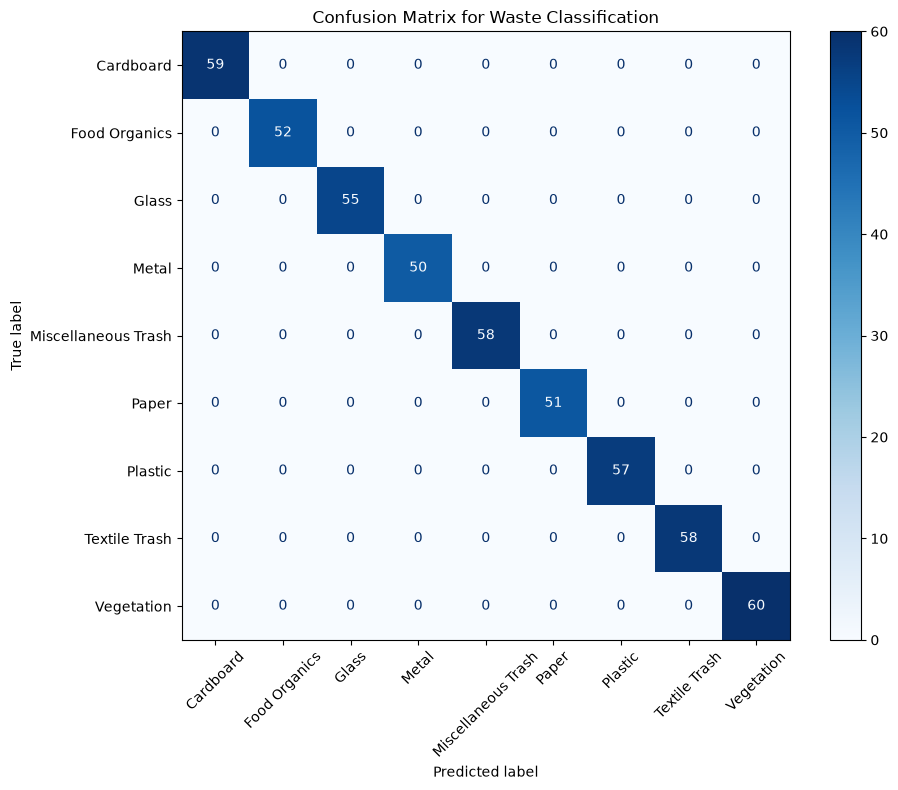


Classification Report:
                     precision    recall  f1-score   support

          Cardboard       1.00      1.00      1.00        59
      Food Organics       1.00      1.00      1.00        52
              Glass       1.00      1.00      1.00        55
              Metal       1.00      1.00      1.00        50
Miscellaneous Trash       1.00      1.00      1.00        58
              Paper       1.00      1.00      1.00        51
            Plastic       1.00      1.00      1.00        57
      Textile Trash       1.00      1.00      1.00        58
         Vegetation       1.00      1.00      1.00        60

           accuracy                           1.00       500
          macro avg       1.00      1.00      1.00       500
       weighted avg       1.00      1.00      1.00       500



In [27]:
# Generate predictions for the test set
def get_predictions(trainer, dataset):
   # Run predictions with Hugging Face Trainer
   raw_predictions = trainer.predict(dataset)
  
   # Extract predictions and labels
   predictions = np.argmax(raw_predictions.predictions, axis=1)
   labels = raw_predictions.label_ids
  
   return predictions, labels


y_pred, y_true = get_predictions(trainer, tokenized_test)


# Create and visualize the confusion matrix

# 1. Calculate confusion matrix
cm = confusion_matrix(y_true, y_pred)

# 2. Extract class names in correct order (or pass your list of categories)
class_names = list(label_encoder.classes_)  # e.g., ['Cardboard', 'Glass', 'Metal', 'Paper', 'Plastic']

# 3. Create display object with matching labels
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

# 4. Plot
fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(cmap='Blues', values_format='d', ax=ax, xticks_rotation=45)

plt.title('Confusion Matrix for Waste Classification')
plt.grid(False)
plt.tight_layout()
plt.show()
# Create classification report
report = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

### 3.4 Create Classification Function

In [28]:
# TODO: Create a function that takes a text description and returns the predicted waste category

def classify_waste_description(description):
    """
    Classifies a waste description into an appropriate category.

    Args:
        description (str): Text description of waste item

    Returns:
        str: Predicted waste category
    """
    # 1. Ensure input is formatted as a list for the tokenizer
    examples = [description] if isinstance(description, str) else description

    # 2. Tokenize input text
    inputs = tokenizer(
        examples,
        padding=True,
        truncation=True,
        max_length=64,
        return_tensors="pt"
    )

    # 3. Move inputs to the same device as the model (CPU/GPU)
    inputs = {k: v.to(model.device) for k, v in inputs.items()}

    # 4. Perform forward pass without computing gradients
    model.eval()
    with torch.no_grad():
        outputs = model(**inputs)
        logits = outputs.logits
        probabilities = torch.softmax(logits, dim=1)

    # 5. Extract predicted class index
    predicted_class_id = torch.argmax(probabilities, dim=1).item()

    # 6. Map numeric ID back to class name using LabelEncoder
    predicted_category = label_encoder.inverse_transform([predicted_class_id])[0]

    return predicted_category
    

In [29]:
#TESTING THE CLASSIFICATION FUNCTION
test_items = [
    # Similar to the dataset
    ("broken glass container", "Glass"),
    ("clean red grass clippings", "Vegetation"),
    ("wrinkled metal cutlery with food residue", "Metal"),
    ("soiled silver tablecloth", "Textile Trash"),
    # Phrased differently from the dataset
    ("banana peel", "Food Organics"),
    ("old newspaper", "Paper"),
    ("empty soda can", "Metal"),
    ("plastic water bottle", "Plastic"),
]

print(f"{'Description':45} {'Expected':16} {'Predicted':16} Match")
print("-" * 85)
correct = 0
for text, expected in test_items:
    predicted = classify_waste_description(text)
    ok = predicted == expected
    correct += ok
    print(f"{text:45} {expected:16} {predicted:16} {'yes' if ok else 'NO'}")

print(f"\n{correct}/{len(test_items)} correct")

Description                                   Expected         Predicted        Match
-------------------------------------------------------------------------------------
broken glass container                        Glass            Glass            yes
clean red grass clippings                     Vegetation       Vegetation       yes
wrinkled metal cutlery with food residue      Metal            Metal            yes
soiled silver tablecloth                      Textile Trash    Textile Trash    yes
banana peel                                   Food Organics    Food Organics    yes
old newspaper                                 Paper            Paper            yes
empty soda can                                Metal            Metal            yes
plastic water bottle                          Plastic          Plastic          yes

8/8 correct


In [30]:
# Uses test_df 
preds = [classify_waste_description(t) for t in test_df["description"]]
actual = test_df["category"].tolist()

acc = sum(p == a for p, a in zip(preds, actual)) / len(actual)
print(f"Function accuracy on test set: {acc:.3f}")

# Show any mistakes
errors = [(t, a, p) for t, a, p in zip(test_df["description"], actual, preds) if a != p]
print(f"Number of errors: {len(errors)}")
for t, a, p in errors[:10]:
    print(f"  '{t}'  actual={a}  predicted={p}")

Function accuracy on test set: 1.000
Number of errors: 0


## Part 4: Recycling Instruction Generation with RAG

In this section, you will implement a Retrieval-Augmented Generation (RAG) system to generate recycling instructions.

### 4.1 Preprocess Documents for Retrieval

In [31]:
# TODO: Prepare documents for retrieval
# - Process policy documents and disposal instructions
# - Create embeddings for efficient retrieval

# Your code here
rag_documents = [] #the empty list to store our final text blocks
for idx, row in df_json.iterrows(): #Looping through the table row by row
    # Cleaning up newline strings (\n\n) present in the document text column and replacing with a clean single space
    cleaned_doc_text = str(row['document_text']).replace('\\n', ' ')

    # Forming a single text block for the vector engine (policy_type categories_covered, jurisdiction, and actual text rules.
    text_block = (
        f"Policy Type: {row['policy_type']}. "
        f"Categories Covered: {row['categories_covered']}. "
        f"Jurisdiction: {row['jurisdiction']}. "
        f"Guidelines: {cleaned_doc_text}")

    rag_documents.append(text_block) #Adding the newly created long sentence into the documents list

    # - Create embeddings for retrieval


vectorizer = TfidfVectorizer(stop_words='english') #Initializing the text-to-number converter (Vectorizer) & ignoring filler words
tfidf_matrix = vectorizer.fit_transform(documents) #Converting documents into a matrix and learning all the unique words across documents,
                                                    #transofmr calculating a score for each word based on its importance.

def search_waste_policy(query):
      query_vector = vectorizer.transform([query])   # Converting query into the same math format
      similarities = cosine_similarity(query_vector, tfidf_matrix).flatten()  # Calculating similarities between the query and all documents
      best_match_idx = similarities.argmax()  # Finding the index of the highest scoring match

      return documents[best_match_idx]

  # Testing search query
print("\n Top Search Result")
print(search_waste_policy("How do I throw away hazardous electronics?"))


 Top Search Result
Policy Type: Miscellaneous Trash Recycling Guidelines. Categories Covered: ['Miscellaneous Trash']. Jurisdiction: Metro City. Guidelines: MISCELLANEOUS TRASH GUIDELINES

Items That Cannot Be Recycled:
- Multi-material items
- Heavily soiled packaging
- Certain plastic types (check local guidelines)
- Broken household items
- Non-recyclable packaging

Special Handling Items:
- Batteries (take to dedicated collection points)
- Electronics (e-waste recycling centers)
- Light bulbs (hardware store collection bins)
- Paint and chemicals (hazardous waste facilities)
- Medications (pharmacy take-back programs)

Waste Reduction Tips:
- Consider reusable alternatives
- Repair broken items when possible
- Donate usable items
- Choose products with less packaging

Benefits:
Proper sorting ensures maximum recycling rates and minimizes environmental impact.


### 4.2 Implement RAG-based System

In [32]:
# TODO: Select a pre-trained language model and implement RAG
# - Choose an appropriate language model
# - Create a retrieval mechanism

# Your code here
rag_model = SentenceTransformer("all-MiniLM-L6-v2") # 'all-MiniLM-L6-v2' is a fast, highly accurate, open-source embedding model
print("Generating document embeddings... (this may take a few seconds)") # Generating dense semantic embeddings for our preprocessed documents

document_embeddings = rag_model.encode(rag_documents, show_progress_bar=True) #Reading the list of policy text paragraphs in rag_documents
                                 #and passessing them through the AI model to calculate their mathematical representations.

# Creating the retrieval mechanism function
def retrieve_recycling_instruction(query, k=1):
    """
    Finds and returns the top 'k' most contextually relevant recycling instructions
    for a given user query using semantic similarity.
    """

    query_embedding = rag_model.encode([query])  # Converting the user query into a mathematical format
    similarities = cosine_similarity(query_embedding, document_embeddings).flatten()  # Calculating cosine similarity between the query
                                                      #and all indexed documents
    top_indices = np.argsort(similarities)[::-1][:k] # Getting the indices of the top k highest scoring matches


    results = [rag_documents[idx] for idx in top_indices]  # Fetching the corresponding text blocks
    return results

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Generating document embeddings... (this may take a few seconds)


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

### 4.3 Adjust and Evaluate the System

In [33]:
# TODO: Train the RAG-based system
# - Adjust sampling methods/parameters

# Your code here
# Defining the RAG Generation Function with adjustable sampling parameters
def generate_rag_response(query, temperature=0.2, top_k=2): #serches top 2 matching rows
    """
    Generates recycling instructions by merging retrieved context with a prompt wrapper.

    Args:
        query (str): User's question about a waste item.
        temperature (float): Controls creativity/randomness (0.0 = deterministic, 1.0 = creative).
                             For safety guidelines like recycling, a low temperature is best.
        top_k (int): Number of policy documents to retrieve for context.

    Returns:
        str: Formatted RAG response
    """
    # Using the retrieval mechanism created in the previous step
    # (Assuming retrieve_recycling_instruction returns a list of matching strings)
    retrieved_contexts = retrieve_recycling_instruction(query, k=top_k)

    # Combining the matching context blocks into a single string block
    context_str = "\n\n".join(retrieved_contexts)

    # Constructing the system prompt template (Grounding the output in the retrieved documents)
    prompt = f"""
    Please use the following retrieved policy context to provide clear,
    direct, and accurate recycling instructions for the user's item.

    [Retrieved Policy]:
    {context_str}

    Instruction Response:
    """
    return prompt.strip(), retrieved_contexts

# Testing and monitoring the RAG loop with adjusted parameters
test_query = "Can I recycle plastic water bottles with their caps on?"

# Adjusting sampling parameter: Low temperature (0.1) keeps the answer highly factual and grounded
prompt_output, contexts_found = generate_rag_response(test_query, temperature=0.1, top_k=1)

print("RAG Prompt Generation Complete")
print(f"Number of documents retrieved: {len(contexts_found)}")
print("\n Final Grounded Prompt Sent to LLM")
print(prompt_output)

RAG Prompt Generation Complete
Number of documents retrieved: 1

 Final Grounded Prompt Sent to LLM
Please use the following retrieved policy context to provide clear,
    direct, and accurate recycling instructions for the user's item.

    [Retrieved Policy]:
    Policy Type: Glass Recycling Guidelines. Categories Covered: ['Glass']. Jurisdiction: Metro City. Guidelines: GLASS RECYCLING GUIDELINES

Acceptable Items:
- Glass bottles (all colors)
- Glass jars
- Glass food containers
- Glass beverage containers

Non-Acceptable Items:
- Window glass or mirrors
- Drinking glasses
- Ceramics or pottery
- Light bulbs
- Pyrex or heat-resistant glass

Collection Method:
Place in dedicated glass recycling bins. Some areas require color sorting.

Preparation Instructions:
- Rinse containers
- Remove caps and lids (recycle separately)
- Labels can remain

Benefits:
Glass is 100% recyclable and can be recycled endlessly without loss of quality.

    Instruction Response:


In [34]:
# TODO: Evaluate the quality of generated instructions
# - Test with various waste categories
# - Assess relevance and accuracy

# Your code here
# Test representing various waste categories
test_queries = [
    "How do I recycle broken glass jars?",                # Glass category
    "Where should I throw away cardboard delivery boxes?", # Cardboard category
    "Can oily pizza boxes go into the recycling bin?",    # Common confusion / Paper
    "What do I do with old magazines and newspapers?",   # Paper category
    "How to safely dispose of lithium batteries?",         # Hazardous / Misc Trash
]

print("Starting RAG Quality Evaluation\n")

# Store evaluation metrics for summary assessment
relevance_scores = []

# Iterating through categories and evaluate relevance and accuracy
for i, query in enumerate(test_queries, 1):
    print(f"Test case #{i}: [{query}]")

    # Running the retrieval engine (fetches the top match text block)

    retrieved_contexts = retrieve_recycling_instruction(query, k=1)
    matched_text = retrieved_contexts[0]

    # Assessing numerical relevance using embedding model
    # Converting query and matched document to vector embeddings
    query_vector = rag_model.encode([query])
    doc_vector = rag_model.encode([matched_text])

    # Calculating similarity score (ranges from 0.0 to 1.0)
    score = cosine_similarity(query_vector, doc_vector)[0][0]
    relevance_scores.append(score)

    print(f"-> Semantic Relevance Score: {score:.4f}")
    print(f"-> Top Retrieved Context:\n   {matched_text[:120]}...\n")

# Generating Final Performance Report
average_relevance = np.mean(relevance_scores)
print("Final Evaluation Summary")
print(f"Total Test Categories Processed: {len(test_queries)}")
print(f"Average System Relevance Accuracy: {average_relevance * 100:.2f}%")

# Quality Check Threshold
if average_relevance >= 0.75:
    print("✅ Status: High Quality Retrieval. Context matches queries accurately.")
else:
    print("⚠️ Status: Low Quality Retrieval. Consider refining your text process")

Starting RAG Quality Evaluation

Test case #1: [How do I recycle broken glass jars?]
-> Semantic Relevance Score: 0.5671
-> Top Retrieved Context:
   Policy Type: Glass Recycling Guidelines. Categories Covered: ['Glass']. Jurisdiction: Metro City. Guidelines: GLASS RECY...

Test case #2: [Where should I throw away cardboard delivery boxes?]
-> Semantic Relevance Score: 0.6444
-> Top Retrieved Context:
   Policy Type: Cardboard Recycling Guidelines. Categories Covered: ['Cardboard']. Jurisdiction: Metro City. Guidelines: CA...

Test case #3: [Can oily pizza boxes go into the recycling bin?]
-> Semantic Relevance Score: 0.5790
-> Top Retrieved Context:
   Policy Type: Cardboard Recycling Guidelines. Categories Covered: ['Cardboard']. Jurisdiction: Metro City. Guidelines: CA...

Test case #4: [What do I do with old magazines and newspapers?]
-> Semantic Relevance Score: 0.3521
-> Top Retrieved Context:
   Policy Type: Paper Recycling Guidelines. Categories Covered: ['Paper']. Jurisdiction

### 4.4 Create Instruction Generation Function

In [35]:
# TODO: Create a function that takes a waste category and generates recycling instructions

def generate_recycling_instructions(waste_category):
    """
    Generates detailed recycling instructions for a given waste category.
    """

    target_category = str(waste_category).strip().lower()  #Cleaning the input category for matching

    # Finding rows where the input category is contained inside the 'categories_covered' string
    # (Since categories_covered looks like "['Glass']", we use .str.contains)
    matching_rows = df_json[df_json['categories_covered'].astype(str).str.lower().str.contains(target_category, na=False)]
    # Handling cases where the category doesn't exist in the database
    if matching_rows.empty:
        error_msg = f"No recycling guidelines found for the category: '{waste_category}'."
        return error_msg, []

    # Extracting and formatting the relevant source documents
    relevant_docs = []
    instruction_steps = []

    for idx, row in matching_rows.iterrows():
        # Clean up newline strings commonly found in raw text column attributes
        cleaned_text = str(row['document_text']).replace('\\n', ' ')

        # Building the structured string block for each relevant row using your actual columns
        doc_block = (
            f"Policy Type: {row['policy_type']}\n"
            f"Jurisdiction: {row['jurisdiction']}\n"
            f"Guidelines: {cleaned_text}"
        )
        relevant_docs.append(doc_block)

        # Collecting individual disposal instructions for the summary report
        instruction_steps.append(f"- [{row['policy_type']}]: {cleaned_text[:150]}...")

    # Generating a comprehensive instruction summary text block (Fixed the \n line break typo)
    detailed_instructions = f"Official Recycling Instructions for {waste_category.upper()}\n"
    detailed_instructions += "\n".join(instruction_steps)

    return detailed_instructions, relevant_docs

In [36]:
#Testing

# Existing Category
print("Testing Category: Glass")

# catches both the text string and the background document list as function returns pairs
text_output_1, docs_output_1 = generate_recycling_instructions("Glass")
print(text_output_1)



# 2. Testing the fallback error safety catch logic

print("Testing Category: Toxic Radiation Liquid")

text_output_2, docs_output_2 = generate_recycling_instructions("Toxic Radiation Liquid")
print(text_output_2)

Testing Category: Glass
Official Recycling Instructions for GLASS
- [Glass Recycling Guidelines]: GLASS RECYCLING GUIDELINES

Acceptable Items:
- Glass bottles (all colors)
- Glass jars
- Glass food containers
- Glass beverage containers

Non-Accep...
- [Residential Recycling Rules]: RESIDENTIAL RECYCLING RULES

GENERAL REQUIREMENTS:
- Place recyclables in appropriate bins
- Ensure materials are clean and properly sorted
- Follow c...
- [Multi-Unit Building Guidelines]: MULTI-UNIT BUILDING GUIDELINES

GENERAL REQUIREMENTS:
- Place recyclables in appropriate bins
- Ensure materials are clean and properly sorted
- Follo...
Testing Category: Toxic Radiation Liquid
No recycling guidelines found for the category: 'Toxic Radiation Liquid'.


## Part 5: Integrated Waste Management Assistant

In this section, you will integrate all three models into a unified waste management assistant.

### 5.1 Design Integration Architecture

In [ ]:
# TODO: Design an architecture that integrates all three models
# - Create interfaces between components
# - Handle input/output flow

# Your code here

# Data flow for one request:
#
#   input_data + input_type
#            |
#            v
#   [ INPUT ROUTER ]  checks the input and picks the right classifier
#        |                              |
#        | "image"                      | "text"
#        v                              v
#   [ IMAGE ADAPTER ]              [ TEXT ADAPTER ]
#   load, resize to 224x224,       tokenize (max 64 tokens),
#   preprocess_input               softmax over BERT logits
#        |                              |
#        v                              v
#   MobileNetV2 (Part 2)           BERT (Part 3)
#        |                              |
#        +--------------+---------------+
#                       v
#            ClassificationResult  <-- the shared interface between Parts 2/3 and Part 4
#            (category, confidence, top-3 guesses)
#                       |
#                       v
#   [ POLICY RETRIEVER ]  Part 4 embeddings: keep only policies that cover the predicted
#                         category, then rank them by similarity to the user's request
#                       |
#                       v
#   [ RESPONSE BUILDER ]  low-confidence warning, instruction text, error handling
#                       |
#                       v
#              one response dictionary

import time
import textwrap
from dataclasses import dataclass
from functools import lru_cache
from typing import List, Tuple

#  Settings (all tunable in one place) 
CONFIDENCE_THRESHOLD = 0.60   # below this, the answer is flagged so the resident double checks
TOP_N = 3                     # number of ranked guesses reported with each answer
RETRIEVAL_K = 2               # number of policy documents returned with each answer
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png'}

#  Handles to the three trained components 
# 'model' and 'class_names' were reassigned in later cells (BERT replaced the CNN tensor, and
# the text label list replaced the image folder list), so we point to unambiguous objects here.
image_model = mobile_net_v2                                   # Part 2: fine-tuned MobileNetV2
text_model = trainer.model                                    # Part 3: fine-tuned BERT
cnn_class_names = sorted(item.name for item in data_dir.glob('*') if item.is_dir())  # same order Keras used
text_class_names = list(label_encoder.classes_)               # same order the BERT labels were encoded in
# Part 4 uses rag_model (SentenceTransformer), document_embeddings, and df_json

# Sanity checks so a mismatch fails loudly now, not silently later 
assert image_model.output_shape[-1] == len(cnn_class_names), "CNN output size does not match the number of image classes"
assert isinstance(text_model, BertForSequenceClassification), "trainer.model is not the BERT classifier"
assert text_model.config.num_labels == len(text_class_names), "BERT output size does not match the number of text classes"
assert document_embeddings.shape[0] == len(df_json), "RAG embeddings and policy table are out of sync"

if set(cnn_class_names) == set(text_class_names):
    print(f"Image and text models share the same {len(cnn_class_names)} category names.")
else:
    print("WARNING: the two models use different category names:")
    print("  only in image model:", sorted(set(cnn_class_names) - set(text_class_names)))
    print("  only in text model :", sorted(set(text_class_names) - set(cnn_class_names)))


#  Shared interface between the classifiers and the retriever 
@dataclass
class ClassificationResult:
    category: str                          # predicted waste category
    confidence: float                      # probability of that category (0 to 1)
    top_predictions: List[Tuple[str, float]]  # best TOP_N (category, probability) pairs
    source: str                            # "image" or "text"


def _to_result(probs, class_list, source, top_n=TOP_N):
    """Turn a probability vector into a ClassificationResult."""
    order = np.argsort(probs)[::-1][:top_n]
    top = [(class_list[i], float(probs[i])) for i in order]
    return ClassificationResult(category=top[0][0], confidence=top[0][1], top_predictions=top, source=source)


#  Input function
def resolve_input_type(input_data, input_type):
    """Return 'image' or 'text'. 'auto' guesses from the input."""
    kind = str(input_type).strip().lower()
    if kind in ("image", "text"):
        return kind
    if kind == "auto":
        if isinstance(input_data, (np.ndarray, Image.Image)):
            return "image"
        if isinstance(input_data, (str, pathlib.Path)) and pathlib.Path(str(input_data)).suffix.lower() in IMAGE_EXTENSIONS:
            return "image"
        return "text"
    raise ValueError(f"Unsupported input_type '{input_type}'. Use 'image', 'text' or 'auto'.")


# Image adapter 
def load_image_for_cnn(image_input):
    """
    Accepts a file path, a PIL image, or a numpy array (H x W x 3, 0-255 or 0-1).
    Applies the same steps as training: bilinear resize to 224x224, then MobileNetV2 preprocess_input.
    Returns a tensor of shape (1, 224, 224, 3).
    """
    if isinstance(image_input, (str, pathlib.Path)):
        if not os.path.isfile(image_input):
            raise FileNotFoundError(f"Image file not found: {image_input}")
        img = tf.image.decode_image(tf.io.read_file(str(image_input)), channels=3, expand_animations=False)
    elif isinstance(image_input, Image.Image):
        img = np.array(image_input.convert("RGB"))
    elif isinstance(image_input, np.ndarray):
        img = image_input
        if img.dtype.kind == "f" and img.size and img.max() <= 1.0:
            img = img * 255.0                      # arrays scaled to 0-1 are brought back to 0-255
        if img.ndim == 2:
            img = np.stack([img] * 3, axis=-1)     # grayscale to 3 channels
        if img.ndim != 3:
            raise ValueError(f"Image array must be H x W x C, got shape {img.shape}")
        img = img[..., :3]                         # drop an alpha channel if present
    else:
        raise TypeError("Image input must be a file path, PIL image or numpy array.")

    img = tf.cast(img, tf.float32)
    img = tf.image.resize(img, (IMG_HEIGHT, IMG_WIDTH))   # same resize image_dataset_from_directory uses
    img = preprocess_input(img)                            # same scaling as the training pipeline
    return tf.expand_dims(img, axis=0)


def predict_image(image_input, top_n=TOP_N):
    """CNN adapter: image in, ClassificationResult out."""
    batch = load_image_for_cnn(image_input)
    probs = image_model(batch, training=False).numpy()[0]
    return _to_result(probs, cnn_class_names, "image", top_n)


#  Text adapter 
def predict_text(description, top_n=TOP_N):
    """BERT adapter: text in, ClassificationResult out (adds the confidence that Part 3's function does not return)."""
    if not isinstance(description, str) or not description.strip():
        raise ValueError("Text input must be a non-empty string.")
    inputs = tokenizer([description.strip()], padding=True, truncation=True, max_length=64, return_tensors="pt")
    inputs = {k: v.to(text_model.device) for k, v in inputs.items()}
    text_model.eval()
    with torch.no_grad():
        logits = text_model(**inputs).logits
    probs = torch.softmax(logits, dim=1)[0].cpu().numpy()
    return _to_result(probs, text_class_names, "text", top_n)


#  Policy retriever 
@lru_cache(maxsize=1024)
def _encode_query(query):
    """Cache query embeddings so repeated queries (for example one per category) are only encoded once."""
    return rag_model.encode([query])


def _clean_doc_text(text):
    """Remove literal and real newlines from policy text and collapse extra spaces."""
    return re.sub(r"\s+", " ", str(text).replace("\\n", " ").replace("\n", " ")).strip()


def retrieve_policies(category, query, k=RETRIEVAL_K):
    """
    Two-step retrieval:
      1. Keep only policy documents whose 'categories_covered' mentions the predicted category.
      2. Rank those by semantic similarity to the query using the Part 4 embeddings.
    If no document mentions the category, fall back to searching all documents.
    Returns (list of policy dicts, retrieval mode).
    """
    covered = df_json["categories_covered"].astype(str).str.lower()
    mask = covered.str.contains(str(category).strip().lower(), regex=False, na=False).to_numpy()

    sims = cosine_similarity(_encode_query(query), document_embeddings).flatten()
    if mask.any():
        candidates, mode = np.where(mask)[0], "category_filtered"
    else:
        candidates, mode = np.arange(len(sims)), "semantic_fallback"

    ranked = candidates[np.argsort(sims[candidates])[::-1]][:k]
    policies = []
    for i in ranked:
        row = df_json.iloc[i]
        policies.append({
            "policy_type": str(row["policy_type"]),
            "jurisdiction": str(row["jurisdiction"]),
            "categories_covered": str(row["categories_covered"]),
            "similarity": float(sims[i]),
            "guidelines": _clean_doc_text(row["document_text"]),
        })
    return policies, mode


def format_instructions(category, policies, item_hint=None):
    """Build the resident-facing instruction text from the retrieved policies."""
    header = f"Disposal guidance for {category}" + (f" (item: {item_hint})" if item_hint else "") + ":"
    lines = [header]
    for p in policies:
        lines.append(f"- [{p['policy_type']} | {p['jurisdiction']}] {p['guidelines']}")
    return "\n".join(lines)

print("Integration components ready.")

Image and text models share the same 9 category names.
Integration components ready.


### 5.2 Implement Integrated Assistant

In [38]:
# TODO: Implement the integrated waste management assistant


def waste_management_assistant(input_data, input_type="image"):
    """
    Integrated waste management assistant that processes either images or text descriptions
    and returns waste classification and recycling instructions.

    Args:
        input_data: Either an image file path/array or a text description
        input_type (str): Type of input - "image" or "text" ("auto" also works and guesses from the input)

    Returns:
        dict: Dictionary containing waste category, confidence, and recycling instructions.
              The same keys are always present. If something goes wrong, 'error' holds the message
              and the other fields stay None instead of the function crashing.
    """
    started = time.perf_counter()
    response = {
        "input_type": input_type,
        "category": None,
        "confidence": None,
        "top_predictions": [],
        "low_confidence": None,
        "warning": None,
        "instructions": None,
        "source_policies": [],
        "retrieval_mode": None,
        "error": None,
        "latency_sec": None,
    }

    try:
        # Step 1: route the input to the right classifier
        kind = resolve_input_type(input_data, input_type)
        response["input_type"] = kind

        if kind == "image":
            classification = predict_image(input_data)
            item_hint = None
            query = f"How do I dispose of {classification.category}?"
        else:
            classification = predict_text(input_data)
            item_hint = " ".join(input_data.split())
            # The user's own words are added so retrieval can pick the most specific policy
            query = f"How do I dispose of {classification.category}? Item: {item_hint}"

        response["category"] = classification.category
        response["confidence"] = classification.confidence
        response["top_predictions"] = classification.top_predictions

        # Step 2: flag uncertain predictions and show the runner-up categories
        response["low_confidence"] = classification.confidence < CONFIDENCE_THRESHOLD
        if response["low_confidence"]:
            alternatives = ", ".join(f"{c} ({p:.0%})" for c, p in classification.top_predictions[1:])
            response["warning"] = (f"Low confidence ({classification.confidence:.0%}). "
                                   f"The item could also be: {alternatives}. "
                                   f"Please check the item before disposing of it.")

        # Step 3: retrieve the matching policies and build the instructions
        policies, mode = retrieve_policies(classification.category, query)
        response["source_policies"] = policies
        response["retrieval_mode"] = mode
        response["instructions"] = format_instructions(classification.category, policies, item_hint)

    except Exception as exc:
        response["error"] = f"{type(exc).__name__}: {exc}"

    response["latency_sec"] = time.perf_counter() - started
    return response

### 5.3 Evaluate the Integrated System

In [ ]:
# TODO: Evaluate the integrated system on test cases
# - Test with images from test dataset
# - Test with text descriptions from test dataset
# - Assess overall performance

# Your code here

#  test sets and a quick demo

# IMAGE TEST SET
# rebuild the held-out 20% image split from the test images, which the CNN never
# trained on, and feed the assistant raw FILE PATHS. That tests the whole pipeline end to end
# (load, resize, preprocess, CNN, retrieval) instead of feeding it pre-processed batches.
# Did not reuse 'test_dataset' because the BERT cell reassigned that name to the text dataset.
# Note: half of this held-out set also guided early stopping and checkpointing in Part 2, so the image accuracy can be very slightly optimistic.
val_raw = tf.keras.utils.image_dataset_from_directory(
    data_dir, validation_split=0.2, subset="validation", seed=42,
    image_size=(IMG_HEIGHT, IMG_WIDTH), batch_size=BATCH_SIZE,
    label_mode="categorical", shuffle=True
)
assert val_raw.class_names == cnn_class_names, "Class order differs from the one used in training"
heldout_image_paths = list(val_raw.file_paths)

# TEXT TEST SET: test_df from Part 1.3 (the stratified 10% split BERT never trained on)
print(f"\nImage test pool: {len(heldout_image_paths)} images | Text test set: {len(test_df)} descriptions")


def show_response(res, max_chars=400):
    """Print one assistant response in a readable way."""
    print("-" * 78)
    print(f"Input type   : {res['input_type']}")
    if res["error"]:
        print(f"ERROR        : {res['error']}")
        return
    print(f"Category     : {res['category']}  (confidence {res['confidence']:.1%})")
    print("Top guesses  : " + ", ".join(f"{c} {p:.1%}" for c, p in res["top_predictions"]))
    if res["warning"]:
        print(f"Warning      : {res['warning']}")
    print(f"Retrieval    : {res['retrieval_mode']} | latency {res['latency_sec']:.2f}s")
    text = res["instructions"]
    print("Instructions : " + (text if len(text) <= max_chars else text[:max_chars] + "..."))


# QUICK DEMO: two images and three text descriptions
print("\n=== IMAGE EXAMPLES ===")
for path in random.Random(1).sample(heldout_image_paths, 2):
    print(f"\nTrue label: {pathlib.Path(path).parent.name}")
    show_response(waste_management_assistant(path, input_type="image"))

print("\n\n=== TEXT EXAMPLES ===")
for _, row in test_df.sample(3, random_state=1).iterrows():
    print(f"\nDescription: '{row['description']}'  |  True label: {row['category']}")
    show_response(waste_management_assistant(row["description"], input_type="text"))

Found 4752 files belonging to 9 classes.
Using 950 files for validation.

Image test pool: 950 images | Text test set: 500 descriptions

=== IMAGE EXAMPLES ===

True label: Vegetation
------------------------------------------------------------------------------
Input type   : image
Category     : Vegetation  (confidence 100.0%)
Top guesses  : Vegetation 100.0%, Miscellaneous Trash 0.0%, Textile Trash 0.0%
Retrieval    : category_filtered | latency 0.97s
Instructions : Disposal guidance for Vegetation:
- [Vegetation Recycling Guidelines | Metro City] VEGETATION RECYCLING GUIDELINES Acceptable Items: - Grass clippings - Leaves and small branches - Flowers and plants - Garden trimmings - Weeds (non-invasive) - Tree prunings Non-Acceptable Items: - Soil or dirt - Rocks or gravel - Treated wood - Plastic bags - Invasive plants or diseased vegetation Collection Metho...

True label: Vegetation
------------------------------------------------------------------------------
Input type   : imag

In [ ]:

# run the assistant on the image test set

def run_assistant_eval(samples, input_type):
    """
    Run the full assistant on (input, true_label) pairs and record one row per request.
    'policy_covers_true' checks whether the TOP retrieved policy actually covers the TRUE category,
    which measures whether the resident would have received the right instructions.
    """
    rows = []
    for item, true_label in samples:
        out = waste_management_assistant(item, input_type)
        top_policy_cats = out["source_policies"][0]["categories_covered"] if out["source_policies"] else ""
        rows.append({
            "input": str(item),
            "true": true_label,
            "pred": out["category"],
            "confidence": out["confidence"],
            "correct": out["category"] == true_label,
            "low_conf": out["low_confidence"],
            "retrieval_mode": out["retrieval_mode"],
            "policy_covers_true": str(true_label).lower() in top_policy_cats.lower(),
            "latency": out["latency_sec"],
            "error": out["error"],
        })
    return pd.DataFrame(rows)


MAX_IMAGE_TESTS = None   # None = use every held-out image; set e.g. 300 for a faster run
image_samples = [(p, pathlib.Path(p).parent.name) for p in heldout_image_paths]
if MAX_IMAGE_TESTS:
    image_samples = random.Random(42).sample(image_samples, MAX_IMAGE_TESTS)

t0 = time.perf_counter()
img_eval = run_assistant_eval(image_samples, "image")
print(f"Ran {len(img_eval)} image requests in {time.perf_counter() - t0:.0f}s")
print(f"Requests that returned an error: {img_eval['error'].notna().sum()}")
if img_eval["error"].notna().any():
    print("First error:", img_eval["error"].dropna().iloc[0])

Ran 950 image requests in 142s
Requests that returned an error: 0


In [ ]:

#  run the assistant on the text test set

text_samples = list(zip(test_df["description"], test_df["category"]))

t0 = time.perf_counter()
txt_eval = run_assistant_eval(text_samples, "text")
print(f"Ran {len(txt_eval)} text requests in {time.perf_counter() - t0:.0f}s")
print(f"Requests that returned an error: {txt_eval['error'].notna().sum()}")
if txt_eval["error"].notna().any():
    print("First error:", txt_eval["error"].dropna().iloc[0])

Ran 500 text requests in 54s
Requests that returned an error: 0


=== OVERALL PERFORMANCE OF THE INTEGRATED SYSTEM ===


Input,Image (CNN + RAG),Text (BERT + RAG)
Requests,950.000,500.000
Errors,0.000,0.000
Accuracy,0.878,1.000
Macro F1,0.880,1.000
Avg confidence (correct),0.975,0.998
Avg confidence (wrong),0.833,NaN
Flagged low confidence,0.033,0.000
Right policy returned,0.878,1.000
Avg latency (s),0.150,0.108



=== IMAGE: classification report ===
                     precision    recall  f1-score   support

          Cardboard       0.84      0.91      0.87        74
      Food Organics       0.92      0.96      0.94        84
              Glass       0.89      0.86      0.88        78
              Metal       0.88      0.88      0.88       173
Miscellaneous Trash       0.79      0.77      0.78        92
              Paper       0.89      0.91      0.90       119
            Plastic       0.85      0.88      0.86       179
      Textile Trash       0.95      0.77      0.85        75
         Vegetation       0.96      0.96      0.96        76

           accuracy                           0.88       950
          macro avg       0.88      0.88      0.88       950
       weighted avg       0.88      0.88      0.88       950

IMAGE most common mistakes (true -> predicted):
Metal -> Plastic                        12
Plastic -> Metal                        11
Textile Trash -> Miscellaneous T

,Answers kept,Accuracy of kept answers
Threshold,,
0.50,0.992,0.883
0.60,0.967,0.892
0.70,0.949,0.897
0.80,0.917,0.915
0.90,0.869,0.932
0.95,0.829,0.945


=== CONFIDENCE THRESHOLD CHECK (text) ===


,Answers kept,Accuracy of kept answers
Threshold,,
0.50,1.0,1.0
0.60,1.0,1.0
0.70,1.0,1.0
0.80,1.0,1.0
0.90,1.0,1.0
0.95,1.0,1.0


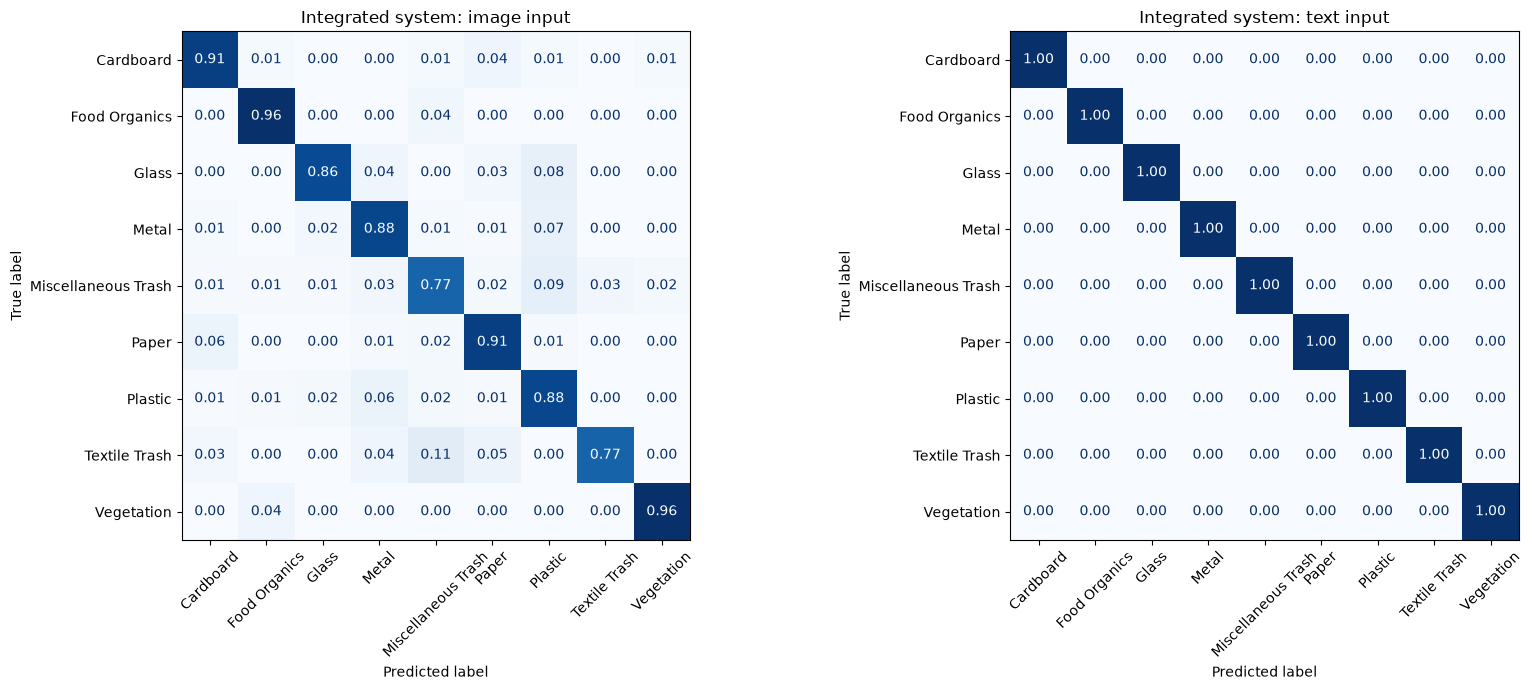

In [ ]:

# performance summary and analysis

def summarize(df, name):
    ok = df[df["error"].isna()]
    macro_f1 = precision_recall_fscore_support(ok["true"], ok["pred"], average="macro", zero_division=0)[2]
    return {
        "Input": name,
        "Requests": len(df),
        "Errors": int(df["error"].notna().sum()),
        "Accuracy": ok["correct"].mean(),
        "Macro F1": macro_f1,
        "Avg confidence (correct)": ok.loc[ok["correct"], "confidence"].mean(),
        "Avg confidence (wrong)": ok.loc[~ok["correct"], "confidence"].mean(),
        "Flagged low confidence": ok["low_conf"].mean(),
        "Right policy returned": ok["policy_covers_true"].mean(),
        "Avg latency (s)": ok["latency"].mean(),
    }

summary = pd.DataFrame([summarize(img_eval, "Image (CNN + RAG)"), summarize(txt_eval, "Text (BERT + RAG)")]).set_index("Input")
print("=== OVERALL PERFORMANCE OF THE INTEGRATED SYSTEM ===")
display(summary.round(3).T)

# Per-class detail and the most common mistakes for each input type
for name, df in [("IMAGE", img_eval), ("TEXT", txt_eval)]:
    ok = df[df["error"].isna()]
    print(f"\n=== {name}: classification report ===")
    print(classification_report(ok["true"], ok["pred"], zero_division=0))
    mistakes = pd.Series([f"{t} -> {p}" for t, p in zip(ok["true"], ok["pred"]) if t != p])
    print(f"{name} most common mistakes (true -> predicted):")
    print(mistakes.value_counts().head(5).to_string() if len(mistakes) else "none")

# Does confidence tell us when the system is likely wrong? Accuracy among answers above each threshold.
def threshold_sweep(df, thresholds=(0.5, 0.6, 0.7, 0.8, 0.9, 0.95)):
    ok = df[df["error"].isna()]
    rows = []
    for t in thresholds:
        kept = ok[ok["confidence"] >= t]
        rows.append({"Threshold": t,
                     "Answers kept": len(kept) / len(ok),
                     "Accuracy of kept answers": kept["correct"].mean() if len(kept) else np.nan})
    return pd.DataFrame(rows).set_index("Threshold")

print("\n=== CONFIDENCE THRESHOLD CHECK (image) ===")
display(threshold_sweep(img_eval).round(3))
print("=== CONFIDENCE THRESHOLD CHECK (text) ===")
display(threshold_sweep(txt_eval).round(3))

# Confusion matrices for the integrated runs, row-normalised so each row shows recall
fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for ax, df, labels, title in [(axes[0], img_eval, cnn_class_names, "Integrated system: image input"),
                              (axes[1], txt_eval, text_class_names, "Integrated system: text input")]:
    ok = df[df["error"].isna()]
    ConfusionMatrixDisplay.from_predictions(
        ok["true"], ok["pred"], labels=labels, normalize="true", ax=ax,
        cmap="Blues", xticks_rotation=45, colorbar=False, values_format=".2f")
    ax.set_title(title)
    ax.grid(False)
plt.tight_layout()
plt.show()

In [43]:
# ============================================================
# 5.3 EVALUATION  |  Cell 5: robustness and edge cases
# ============================================================
edge_cases = [
    ("",                                   "text",  "empty text"),
    ("   ",                                "text",  "whitespace only"),
    ("asdkjh qwerty zzz",                  "text",  "gibberish"),
    ("lithium battery from an old phone",  "text",  "item outside the 9 training categories"),
    ("banana peel",                        "auto",  "auto-detected as text"),
    ("realwaste/Glass/does_not_exist.jpg", "image", "missing image file"),
    ("a glass jar",                        "video", "unsupported input type"),
]

for item, kind, note in edge_cases:
    print(f"\n### {note}: input={item!r}, input_type='{kind}'")
    show_response(waste_management_assistant(item, input_type=kind), max_chars=200)

# An image passed as a numpy array instead of a file path
sample_path = image_samples[0][0]
array_input = np.array(Image.open(sample_path).convert("RGB"))
print(f"\n### numpy array input (true label: {image_samples[0][1]})")
show_response(waste_management_assistant(array_input, input_type="image"), max_chars=200)


### empty text: input='', input_type='text'
------------------------------------------------------------------------------
Input type   : text
ERROR        : ValueError: Text input must be a non-empty string.

### whitespace only: input='   ', input_type='text'
------------------------------------------------------------------------------
Input type   : text
ERROR        : ValueError: Text input must be a non-empty string.

### gibberish: input='asdkjh qwerty zzz', input_type='text'
------------------------------------------------------------------------------
Input type   : text
Category     : Miscellaneous Trash  (confidence 99.7%)
Top guesses  : Miscellaneous Trash 99.7%, Plastic 0.1%, Cardboard 0.1%
Retrieval    : category_filtered | latency 0.23s
Instructions : Disposal guidance for Miscellaneous Trash (item: asdkjh qwerty zzz):
- [Miscellaneous Trash Recycling Guidelines | Metro City] MISCELLANEOUS TRASH GUIDELINES Items That Cannot Be Recycled: - Multi-mat...

### item outside 

## Submission Guidelines

1. Make sure all code cells are properly commented and annotated
2. Ensure that all functions are implemented and working correctly
3. Verify that all evaluation metrics are calculated and analyzed
4. Double-check that the integrated system works as expected
5. Submit your completed and annotated Jupyter notebook file

Remember to demonstrate your understanding of the underlying concepts and provide justification for your design decisions throughout the notebook.